<a href="https://colab.research.google.com/github/AlaaTaima/plant-model/blob/alaa/plantmodel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os
base = '/content/drive/MyDrive/plant_project/plantvillage dataset'
print(os.listdir(base))

color_dir  = os.path.join(base, 'color')
classes = sorted(os.listdir(color_dir ))
print(len(classes), 'classes')
print(classes[:5])

['color', 'grayscale']
38 classes
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [3]:
!ls /content/drive/MyDrive/plant_project

'plantvillage dataset'	 plantvillage-dataset.zip


In [4]:
counts = {}
for c in classes:
    folder = os.path.join(color_dir, c)
    counts[c] = len(os.listdir(folder))

print('إجمالي الصور:', sum(counts.values()))
print('أقل class:', min(counts, key=counts.get), min(counts.values()))
print('أكبر class:', max(counts, key=counts.get), max(counts.values()))

إجمالي الصور: 54305
أقل class: Potato___healthy 152
أكبر class: Orange___Haunglongbing_(Citrus_greening) 5507


الحجم: (256, 256) | النمط: RGB


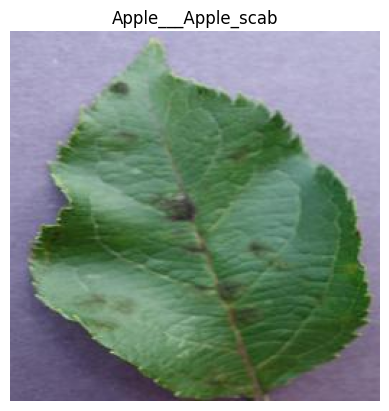

In [5]:
from PIL import Image
import matplotlib.pyplot as plt

folder = os.path.join(color_dir, classes[0])
img_path = os.path.join(folder, os.listdir(folder)[0])
img = Image.open(img_path)

print('الحجم:', img.size, '| النمط:', img.mode)
plt.imshow(img)
plt.title(classes[0])
plt.axis('off')
plt.show()

In [6]:
#بناء جدول لكل الصور
import hashlib
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

rows = []
for c in tqdm(classes):
    folder = os.path.join(color_dir, c)
    for name in os.listdir(folder):
        p = os.path.join(folder, name)
        row = {"path": p, "label": c, "ext": os.path.splitext(name)[1].lower(),
               "bytes": os.path.getsize(p), "width": None, "height": None,
               "mode": None, "corrupted": False, "hash": None}
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                row["width"], row["height"] = im.size
                row["mode"] = im.mode
            row["hash"] = md5(p)
        except Exception:
            row["corrupted"] = True
        rows.append(row)

df = pd.DataFrame(rows)
print(df.shape)
df.head()

  0%|          | 0/38 [00:00<?, ?it/s]

(54305, 9)


,path,label,ext,bytes,width,height,mode,corrupted,hash
0,/content/drive/MyDrive/plant_project/plantvill...,Apple___Apple_scab,.jpg,9616,256,256,RGB,False,841d0bf56e5ab96bb96b0953c49eb31a
1,/content/drive/MyDrive/plant_project/plantvill...,Apple___Apple_scab,.jpg,10108,256,256,RGB,False,b864c04c6195b89d7d7555311dbc3ca4
2,/content/drive/MyDrive/plant_project/plantvill...,Apple___Apple_scab,.jpg,12005,256,256,RGB,False,2265a73c77faf5468e8b90e6dd67897c
3,/content/drive/MyDrive/plant_project/plantvill...,Apple___Apple_scab,.jpg,19474,256,256,RGB,False,aadb92fad55b3241b30b15d718c95775
4,/content/drive/MyDrive/plant_project/plantvill...,Apple___Apple_scab,.jpg,8897,256,256,RGB,False,d3c6c92c783dcd4398d82979b018d93d


In [7]:
#فحص الملفات
#تقرأ الجدول وتطبع تقريراً عن حالة الداتا
print("ملفات تالفة:", df["corrupted"].sum())
print("حجم صفر:", (df["bytes"] == 0).sum())
print("\nالامتدادات:\n", df["ext"].value_counts())
print("\nأنماط الألوان:\n", df["mode"].value_counts())
print("\nالأبعاد:\n", df.groupby(["width", "height"]).size().sort_values(ascending=False).head())

ملفات تالفة: 0
حجم صفر: 0

الامتدادات:
 ext
.jpg     54303
.png         1
.jpeg        1
Name: count, dtype: int64

أنماط الألوان:
 mode
RGB     54304
RGBA        1
Name: count, dtype: int64

الأبعاد:
 width  height
256    256       54305
dtype: int64


In [8]:
#فحص المكرر
ok = df[~df["corrupted"]]

dup_mask = ok.duplicated(subset="hash", keep="first")
print("نسخ زائدة (نفس الملف بالبايت):", dup_mask.sum())

# نفس الصورة تحت فئتين مختلفتين = تعارض في الـ labels
n_labels = ok.groupby("hash")["label"].nunique()
conflict_hashes = n_labels[n_labels > 1].index
print("صور تحت أكثر من فئة:", len(conflict_hashes))

نسخ زائدة (نفس الملف بالبايت): 21
صور تحت أكثر من فئة: 0


In [9]:
#التنظيف
#نبني قائمة بما سيُستبعد، ولا نحذف الملفات من الأصل، فقط نصفّي الجدول
#نعمل بالجدول clean_df بدل نقل الملفات،  وعند بناء الـ dataset سنقرأ الصور من عمود path فقط.
bad = set(df.loc[df["corrupted"], "path"])
bad |= set(ok.loc[dup_mask, "path"])
bad |= set(ok.loc[ok["hash"].isin(conflict_hashes), "path"])

clean_df = df[~df["path"].isin(bad)].drop(columns="corrupted").reset_index(drop=True)
print(f"قبل: {len(df)} | استبعدنا: {len(bad)} | بعد: {len(clean_df)}")

clean_df.to_csv("clean_metadata.csv", index=False)

قبل: 54305 | استبعدنا: 21 | بعد: 54284


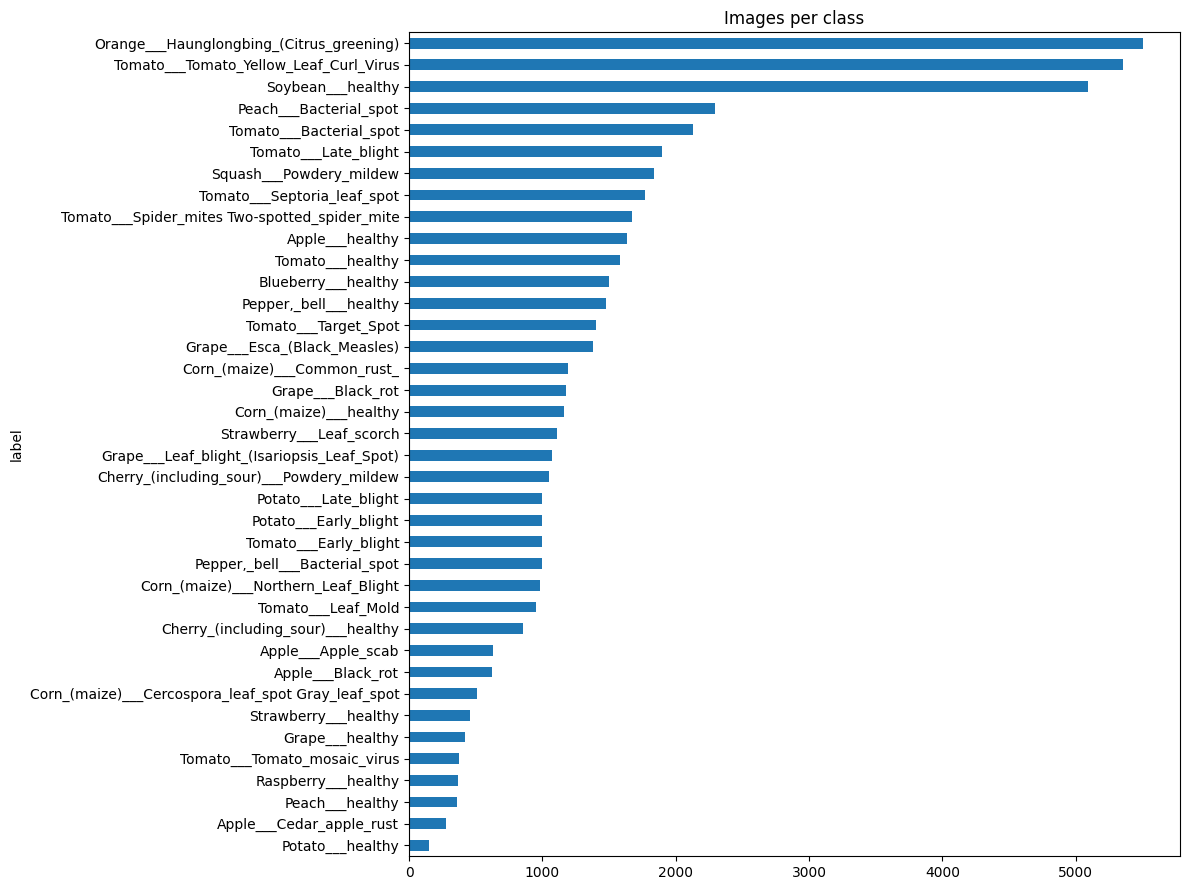

In [10]:
#توزيع الفئات بعد التنظيف

import matplotlib.pyplot as plt
counts = clean_df["label"].value_counts()
plt.figure(figsize=(12, 9))
counts.sort_values().plot(kind="barh")
plt.title("Images per class")
plt.tight_layout()
plt.show()

In [11]:
#معرفة الصورة التي mode = RGBA
print(clean_df[clean_df["mode"] == "RGBA"][["path", "label"]])

                                                    path  \
25001  /content/drive/MyDrive/plant_project/plantvill...   

                        label  
25001  Pepper,_bell___healthy  


alpha min/max: (255, 255)


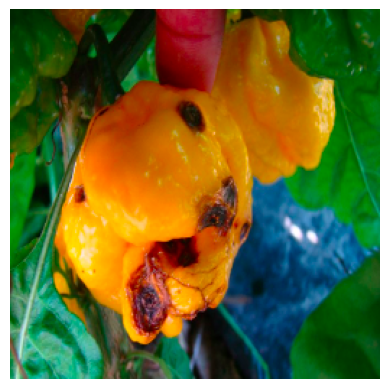

In [12]:
#شاهد الصورة وتحقق هل فيها شفافية فعلية
#النتيجة (255, 255): القناة الرابعة كلها معتمة، والتحويل إلى RGB آمن تماماً.
import matplotlib.pyplot as plt
from PIL import Image

p = clean_df[clean_df["mode"] == "RGBA"]["path"].iloc[0]
im = Image.open(p)

alpha = im.getchannel("A")
print("alpha min/max:", alpha.getextrema())   # (255, 255) = لا شفافية فعلية

plt.imshow(im.convert("RGB"))
plt.axis("off")
plt.show()